In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

In [8]:
df = pd.read_csv('C:/Users/iskit/Desktop/Machine-Learning-Studies/03-MachineLearning/datasets/studyhours.csv')

In [9]:
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Study Hours  33 non-null     float64
 1   Exam Score   33 non-null     float64
dtypes: float64(2)
memory usage: 660.0 bytes


In [5]:
df.describe()

,Study Hours,Exam Score
count,33.000000,33.000000
mean,15.772727,74.612121
std,7.608723,18.711206
min,3.000000,40.000000
25%,9.600000,58.500000
50%,17.400000,78.800000
75%,21.300000,90.800000
max,30.000000,100.000000


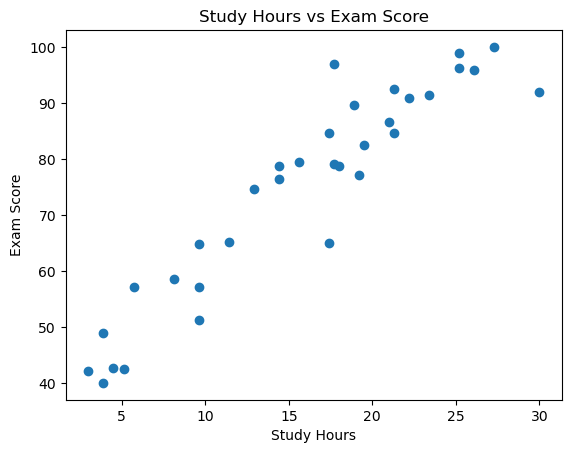

In [12]:
plt.scatter(df['Study Hours'],df['Exam Score'])
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Study Hours vs Exam Score')
plt.show()

In [13]:
# independent and dependent feature

In [17]:
X = df[['Study Hours']]
y = df['Exam Score']

In [18]:
type(X)

pandas.core.frame.DataFrame

In [19]:
type(y)

pandas.core.series.Series

In [20]:
# test-train split

In [21]:
from sklearn.model_selection import train_test_split

In [27]:
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.2, random_state=15)

In [28]:
y_train

18     64.9
1      57.1
2      42.7
32     89.6
6      77.1
3      65.1
29     82.4
26     64.8
9      84.6
4      78.7
28     79.1
10     92.4
27     79.5
13    100.0
17     74.7
15     97.0
22     76.5
31     96.2
11     95.9
7      90.8
0      40.0
23     42.2
5      78.8
12     92.0
21     58.5
8      99.0
Name: Exam Score, dtype: float64

In [29]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

In [30]:
# standradize the data set

In [31]:
from sklearn.preprocessing import StandardScaler

In [32]:
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [33]:
# balanced feature values
# efficent gradient descent
# l1,l2

In [34]:
scaler = StandardScaler()

In [35]:
X_train

,Study Hours
18,17.4
1,9.6
2,4.5
32,18.9
6,19.2
3,11.4
29,19.5
26,9.6
9,17.4
4,14.4


In [36]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [37]:
X_train

array([[ 0.11794385],
       [-0.97424848],
       [-1.68837424],
       [ 0.32798083],
       [ 0.36998823],
       [-0.7222041 ],
       [ 0.41199563],
       [-0.97424848],
       [ 0.11794385],
       [-0.30213013],
       [ 0.15995124],
       [ 0.66404001],
       [-0.13410054],
       [ 1.50418796],
       [-0.51216711],
       [ 0.15995124],
       [-0.30213013],
       [ 1.21013618],
       [ 1.33615837],
       [ 0.7900622 ],
       [-1.77238903],
       [-1.89841122],
       [ 0.20195864],
       [ 1.88225453],
       [-1.18428547],
       [ 1.21013618]])

In [38]:
X_test

array([[-1.60435944],
       [ 0.62203261],
       [ 0.95809179],
       [-1.52034465],
       [-0.97424848],
       [-1.77238903],
       [ 0.66404001]])

 *** Standard Scaler z testi uyguluyor bu fit kısmıda ortalaması ve standart sapmasının bulunması.
 Bu bilgilerle datanın işleme tutulması is transform işlemi ***

** Niye Scaler Kullanırız ? **

=> Kolonlar arasındaki büyük değer farklılıklarını gidermek için

=> Gradient descent'in daha verimli , daha iyi çalışması için

=> Bir ceza algoritması kullanıyorsak o cezaların düzgün uygulanması için

** Neden eğitim verisinde fit_transform(), test verisinde transform() kullanılır? **

Veri sızıntısını (data leakage) önlemek için.

fit_transform(), eğitim verisinin ortalama ve standart sapma gibi istatistiksel parametrelerini öğrenir ve veriyi bu parametrelere göre dönüştürür.

transform() ise test verisinden yeni parametreler öğrenmeden, eğitim verisinden öğrenilen parametreleri kullanarak test verisini dönüştürür.

Böylece test verisinin bilgileri öğrenme sürecine dahil edilmez ve modelin daha önce görmediği veriler üzerindeki performansı güvenilir şekilde değerlendirilir.

In [41]:
from sklearn.linear_model import LinearRegression

In [42]:
regression = LinearRegression()

Eğer notebook bilgisayarda yavaş çalışıyorsa n_jobs = -1 vererek Bilgisayardaki tüm CPU ' ları kullan diyebilirsiniz 

In [43]:
regression.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [44]:
print('Coefficent: ',regression.coef_)
print('Intercept: ',regression.intercept_)

Coefficent:  [16.17860223]
Intercept:  76.9076923076923


In [48]:
# Denklem => y = 76.91 + 16.18x 
# ** Bunun Standardization Edilmiş Hali Bu **

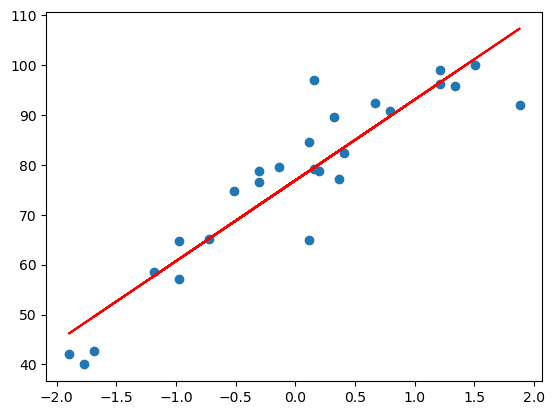

In [47]:
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train),'r')
plt.show()

In [49]:
# x = 20 , y = ?

In [51]:
regression.predict([[20]])

array([400.47973694])

In [52]:
regression.predict(scaler.transform([[20]]))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([84.70590731])

In [53]:
regression.predict(scaler.transform([[10]]))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([62.05187491])

In [55]:
# prediction with test data

In [59]:
y_pred_test = regression.predict(X_test)

In [65]:
y_pred_test

array([50.95139904, 86.97131054, 92.40827832, 52.31064098, 61.14571361,
       48.23291515, 87.65093152])

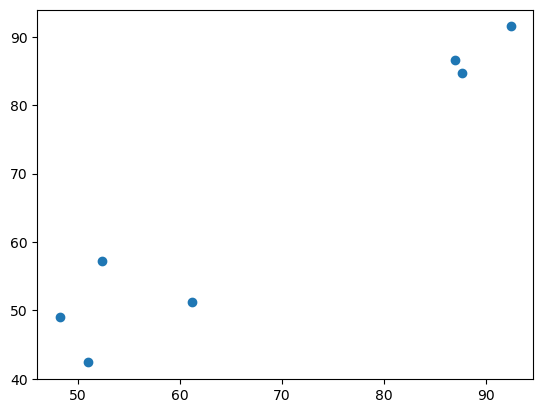

In [60]:
plt.scatter(y_pred_test,y_test)
plt.show()

In [61]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [62]:
mse = mean_squared_error(y_test,y_pred_test)
mae = mean_absolute_error(y_test,y_pred_test)
rmse = np.sqrt(mse)
print('mse: ' , mse)
print('mae: ' , mae)
print('rmse: ' , rmse)

mse:  29.45839048833392
mae:  4.054868128856142
rmse:  5.427558427906043


In [63]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

In [64]:
y_pred_test

array([50.95139904, 86.97131054, 92.40827832, 52.31064098, 61.14571361,
       48.23291515, 87.65093152])

In [66]:
X_test

array([[-1.60435944],
       [ 0.62203261],
       [ 0.95809179],
       [-1.52034465],
       [-0.97424848],
       [-1.77238903],
       [ 0.66404001]])

In [69]:
r2 = r2_score(y_test,y_pred_test)
print('R2 Score',r2)

R2 Score 0.9196596206825491


In [73]:
Adjusted_R2 = 1 - (1-r2)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)
print('Adjusted R2: ' , Adjusted_R2)

Adjusted R2:  0.903591544819059
